# 02 · Inspiration4 blood counts: personal baselines on real astronaut data

**Question.** ARGUS judges each astronaut against **their own** pre-flight baseline (spec 05 §5.2). Is that a sensible approach on real crew data, and does the published post-flight blood count support it?

**Data:** NASA OSDR study **OSD-569**, Inspiration4 Complete Blood Count [SRC-047], downloaded via the OSDR API [SRC-046] by `npm run data:nasa`.
- 4 crew (pseudonymous codes C001–C004).
- 3 pre-flight draws (L-92, L-44, L-3) and 4 post-flight draws (R+1, R+45, R+82, R+194).
- 20 analytes.

**Method:** traditional statistics only.
- Per-person baseline = mean of the 3 pre-flight draws.
- z-score and percent change at R+1.
- Share of values outside the lab reference range.
- With n = 4, results are **descriptive, not inferential**: no p-values are claimed.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from argus_analysis.data import export, REFERENCE
from argus_analysis.ai import summarize
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
lab = export('ref_osdr_lab_values')
print(lab.subject.nunique(), 'crew ·', lab.timepoint.nunique(), 'timepoints ·', lab.analyte.nunique(), 'analytes ·', len(lab), 'values')
lab.head()

4 crew · 7 timepoints · 20 analytes · 553 values


,study_id,subject,timepoint,days_from_launch,phase,analyte,value,unit,ref_min,ref_max,source_id
0,OSD-569,C001,L-92,-92,preflight,absolute_basophils,70.0,cells_per_microliter,0.0,200.0,SRC-047
1,OSD-569,C001,L-92,-92,preflight,absolute_eosinophils,259.0,cells_per_microliter,15.0,500.0,SRC-047
2,OSD-569,C001,L-92,-92,preflight,absolute_lymphocytes,2241.0,cells_per_microliter,850.0,3900.0,SRC-047
3,OSD-569,C001,L-92,-92,preflight,absolute_monocytes,481.0,cells_per_microliter,200.0,950.0,SRC-047
4,OSD-569,C001,L-92,-92,preflight,absolute_neutrophils,2349.0,cells_per_microliter,1500.0,7800.0,SRC-047


In [3]:
pre = lab[lab.phase == 'preflight'].groupby(['subject', 'analyte']).value.agg(base_mean='mean', base_sd='std', n='count').reset_index()
r1 = lab[lab.timepoint == 'R+1'][['subject', 'analyte', 'value', 'unit']].rename(columns={'value': 'r1'})
m = r1.merge(pre, on=['subject', 'analyte'])
m['pct_change'] = 100 * (m.r1 - m.base_mean) / m.base_mean
# n = 3 pre-flight draws → SD is unstable; floor it at 5 % of the mean (same idea as METRIC_TYPICAL_SD in ARGUS).
m['z'] = (m.r1 - m.base_mean) / np.maximum(m.base_sd, 0.05 * m.base_mean.abs())
summary = m.groupby('analyte').agg(mean_pct_change=('pct_change', 'mean'), min_pct=('pct_change', 'min'), max_pct=('pct_change', 'max'),
                                   crew_with_abs_z_over_2=('z', lambda s: int((s.abs() > 2).sum()))).round(1)
summary.sort_values('mean_pct_change', key=abs, ascending=False).head(10)

,mean_pct_change,min_pct,max_pct,crew_with_abs_z_over_2
analyte,,,,
absolute_lymphocytes,-26.8,-48.1,1.9,0
monocytes,25.5,14.1,37.6,2
mpv,-22.8,-91.0,1.9,0
eosinophils,21.5,-15.5,66.7,2
white_blood_cell_count,-14.6,-26.8,-1.6,1
absolute_eosinophils,-13.6,-49.5,38.7,0
absolute_basophils,-11.0,-62.0,24.5,1
platelet_count,10.5,-7.5,48.6,0
rdw,-9.7,-34.4,2.9,0


In [4]:
lab['out_of_range'] = (lab.value < lab.ref_min) | (lab.value > lab.ref_max)
oor = lab.groupby('phase').out_of_range.mean().mul(100).round(1).rename('% of values outside lab reference range')
oor.to_frame()

,% of values outside lab reference range
phase,
postflight,1.6
preflight,4.7


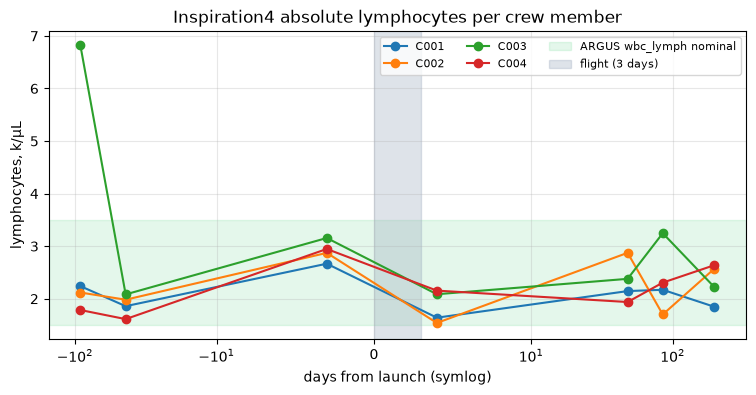

In [5]:
lym = lab[lab.analyte == 'absolute_lymphocytes'].copy()
lym['k_per_uL'] = lym.value / 1000  # ARGUS wbc_lymph unit is k/µL
fig, ax = plt.subplots()
for subj, g in lym.sort_values('days_from_launch').groupby('subject'):
    ax.plot(g.days_from_launch, g.k_per_uL, marker='o', label=subj)
ax.axhspan(1.5, 3.5, color='#22c55e', alpha=0.12, label='ARGUS wbc_lymph nominal')
ax.axvspan(0, 3, color='#94a3b8', alpha=0.3, label='flight (3 days)')
ax.set_xscale('symlog', linthresh=10); ax.set_xlabel('days from launch (symlog)'); ax.set_ylabel('lymphocytes, k/µL')
ax.set_title('Inspiration4 absolute lymphocytes per crew member'); ax.legend(ncol=3, fontsize=8)
plt.show()

In [6]:
# Population range vs personal baseline: how many R+1 values are inside the lab reference range,
# yet more than 2 personal SDs from that person's own baseline?
mm = m.merge(lab[lab.timepoint == 'R+1'][['subject', 'analyte', 'ref_min', 'ref_max']], on=['subject', 'analyte'])
inside_range = (mm.r1 >= mm.ref_min) & (mm.r1 <= mm.ref_max)
hidden = mm[inside_range & (mm.z.abs() > 2)]
print(f"{len(hidden)} of {inside_range.sum()} in-range R+1 values are >2 SD from the person's own baseline")
hidden[['subject', 'analyte', 'base_mean', 'r1', 'pct_change', 'z']].round(2).head(12)

8 of 78 in-range R+1 values are >2 SD from the person's own baseline


,subject,analyte,base_mean,r1,pct_change,z
20,C002,absolute_basophils,31.33,39.0,24.47,3.68
29,C002,lymphocytes,36.40,28.0,-23.08,-2.30
32,C002,monocytes,5.80,7.9,36.21,6.06
34,C002,neutrophils,53.87,60.5,12.31,2.32
45,C003,eosinophils,1.20,2.0,66.67,3.02
52,C003,monocytes,6.83,9.4,37.56,5.69
58,C003,white_blood_cell_count,9.57,7.0,-26.83,-5.37
65,C004,eosinophils,2.63,3.7,40.51,8.10


### Findings (traditional analysis, descriptive)
- The table above shows which analytes moved most at R+1, the day after landing, relative to each person's own pre-flight mean.
- The last cell shows how often a value is **within the population lab range but unusual for that person**. A population range would miss these. This supports ARGUS's personal-baseline design, and the `preflight` baseline in `baselines` is exactly this calculation.
- **Caveats:**
  - 4 people, a 3-day mission, and post-flight draws only: no samples were taken in flight.
  - These are not long-duration microgravity effects.
  - Use this data as a methods check and as context for the AI, not as thresholds.

In [7]:
table = summary.sort_values('mean_pct_change', key=abs, ascending=False).head(8).to_markdown() + '\n\n' + oor.to_frame().to_markdown()
ai = summarize('Inspiration4 (OSD-569) CBC: change at R+1 vs each crew member\'s pre-flight baseline (n=4, descriptive)', table)
print(ai['text'] if ai else 'No AI provider reachable: the computed tables above are the result.')
if ai: print(f"\n(model: {ai['model']})")

No AI provider reachable: the computed tables above are the result.
